# Week 5 – Task 05: CNN vs RNN vs LSTM on Satellite Land-Use Images (EuroSAT)
**Career Launch Pad – AI & Machine Learning, UET Mardan** · Instructor: Mr. Zaheen Ahmad

**Problem:** classify 64×64 Sentinel-2 satellite patches into land-use / land-cover classes.
This is directly relevant to forest monitoring (Forest vs. Pasture vs. Residential ...).

**Dataset:** EuroSAT (RGB) – Helber et al., *IEEE JSTARS* 2019, public on Zenodo
(https://zenodo.org/records/7711810). 27,000 images, 10 classes, 64×64 px, 2,000–3,000 per class.
To keep the dataset *small* (as intended for this task) we use **5 classes × 400 images = 2,000 images**.

**Models** (all trained on the same split, same optimiser, same epochs, same augmentation):
1. CNN  – custom 3-block convolutional network
2. RNN  – vanilla (Elman) RNN reading the image **row by row** (64 time-steps × 192 features)
3. LSTM – same sequence formulation as the RNN, with gated memory

In [1]:
import os, time, json, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             roc_curve, auc, roc_auc_score, classification_report)
from sklearn.preprocessing import label_binarize

# ---- configuration ---------------------------------------------------------------------------
BASE      = Path.cwd()
DATA_DIR  = BASE / "data_raw" / "EuroSAT_RGB"        # extracted from EuroSAT_RGB.zip
OUT_DIR   = BASE / "outputs"; OUT_DIR.mkdir(exist_ok=True)
CLASSES   = ["Forest", "Pasture", "River", "Highway", "Residential"]   # 5 visually related classes
N_PER_CLASS = 400                 # small dataset: 400 images per class -> 2,000 images
SPLIT     = (0.70, 0.15, 0.15)    # train / validation / test
EPOCHS, BATCH, LR, PATIENCE = 40, 64, 1e-3, 8
SEEDS     = [42, 43, 44]          # seed 42 is used for plots; all 3 seeds for mean ± std
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Device: cuda NVIDIA GeForce RTX 3060 Ti


## 1. Load the dataset, document it, and split it (stratified 70 / 15 / 15)
*Why 70/15/15?* With only 2,000 images a 70% train set (1,400) still gives ~280 images/class to learn from,
while 15% validation (300) is large enough for stable early stopping and 15% test (~300, 60/class) gives a
reasonably reliable final estimate. A 80/10/10 split would leave only 200 test images – too noisy for ROC/AUC.

Forest       available= 3000  used=400
Pasture      available= 2000  used=400
River        available= 2500  used=400
Highway      available= 2500  used=400
Residential  available= 3000  used=400


Image tensor: (2000, 64, 64, 3) | resolution: (64, 64) | total images: 2000
train=1399  val=300  test=301
split  Forest  Pasture  River  Highway  Residential
train     280      280    280      280          279
  val      60       60     60       60           60
 test      60       60     60       60           61


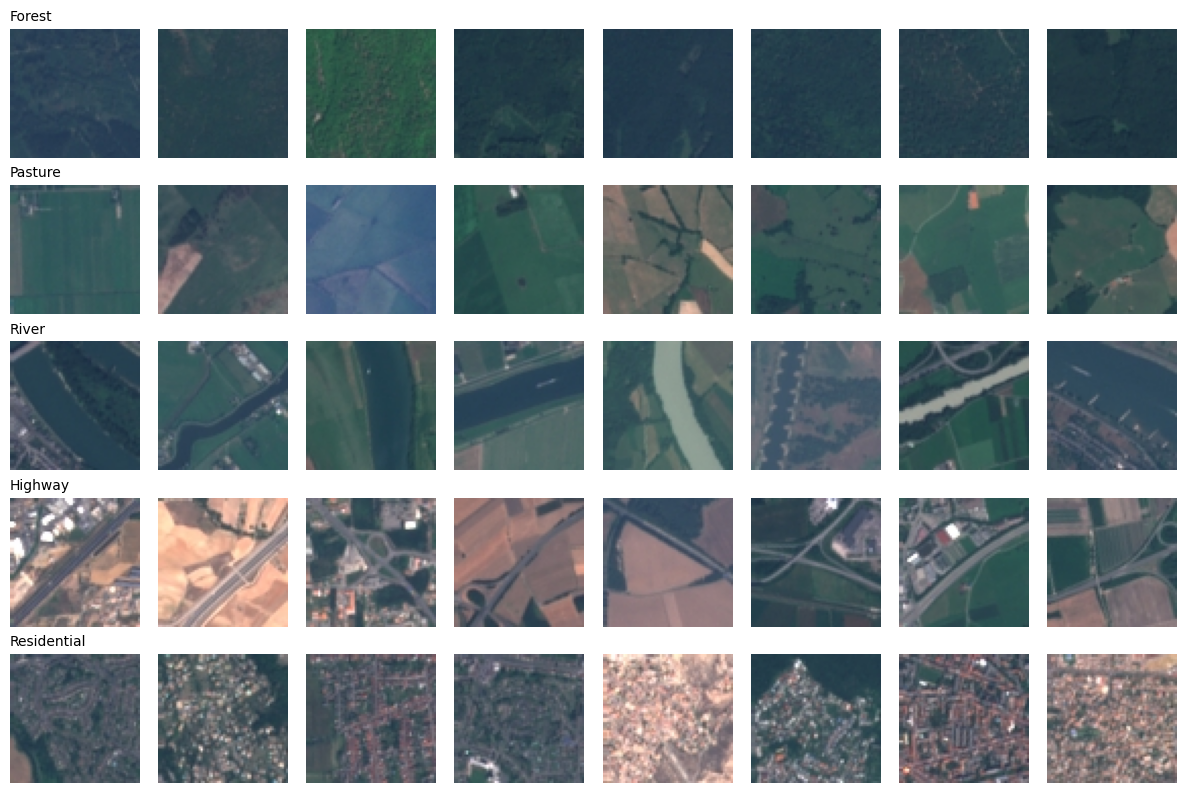

In [2]:
rng = np.random.RandomState(0)
paths, labels = [], []
for ci, c in enumerate(CLASSES):
    files = sorted((DATA_DIR / c).glob("*.jpg"))
    chosen = rng.choice(len(files), N_PER_CLASS, replace=False)
    paths += [files[i] for i in chosen]; labels += [ci] * N_PER_CLASS
    print(f"{c:12s} available={len(files):5d}  used={N_PER_CLASS}")
labels = np.array(labels)

X = np.stack([np.asarray(Image.open(p).convert("RGB")) for p in paths]).astype(np.uint8)  # (N,64,64,3)
print("Image tensor:", X.shape, "| resolution:", X.shape[1:3], "| total images:", len(X))

idx = np.arange(len(X))
tr_idx, tmp_idx = train_test_split(idx, test_size=1 - SPLIT[0], stratify=labels, random_state=0)
va_idx, te_idx  = train_test_split(tmp_idx, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]),
                                   stratify=labels[tmp_idx], random_state=0)
print(f"train={len(tr_idx)}  val={len(va_idx)}  test={len(te_idx)}")
print(pd.DataFrame({"split": ["train", "val", "test"],
                    **{c: [np.sum(labels[i] == k) for i in (tr_idx, va_idx, te_idx)]
                       for k, c in enumerate(CLASSES)}}).to_string(index=False))

# sample grid ---------------------------------------------------------------------------------
fig, ax = plt.subplots(len(CLASSES), 8, figsize=(12, 8))
for r, c in enumerate(CLASSES):
    ids = np.where(labels == r)[0][:8]
    for k, i in enumerate(ids):
        ax[r, k].imshow(X[i]); ax[r, k].axis("off")
    ax[r, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / "samples.png", dpi=130); plt.show()

## 2. Pre-processing
* Pixels rescaled to [0,1] and standardised with the **training-set** channel mean/std (no test leakage).
* Images are already 64×64 (no resizing needed).
* **Augmentation (training only):** random horizontal flip, vertical flip and 90° rotations. Satellite
  imagery has no canonical orientation, so these are label-preserving and fight over-fitting on a small set.
* Data are held as GPU tensors – the whole dataset (≈25 MB) fits in memory, which makes training fast.

In [3]:
Xt = torch.tensor(X).permute(0, 3, 1, 2).float() / 255.0           # (N,3,64,64)
mean = Xt[tr_idx].mean(dim=(0, 2, 3), keepdim=True); std = Xt[tr_idx].std(dim=(0, 2, 3), keepdim=True)
Xt = ((Xt - mean) / std).to(DEVICE)
yt = torch.tensor(labels).to(DEVICE)
print("Channel mean:", mean.flatten().tolist(), "std:", std.flatten().tolist())

def augment(x):
    """Random flips + 90° rotations, applied independently per image (GPU)."""
    B = x.size(0)
    m = torch.rand(B, device=x.device) < 0.5; x = torch.where(m[:, None, None, None], x.flip(3), x)
    m = torch.rand(B, device=x.device) < 0.5; x = torch.where(m[:, None, None, None], x.flip(2), x)
    k = torch.randint(0, 4, (B,), device=x.device); out = x.clone()
    for r in range(1, 4):
        sel = k == r
        if sel.any(): out[sel] = torch.rot90(x[sel], r, dims=(2, 3))
    return out

Channel mean: [0.27796775102615356, 0.34450891613960266, 0.37912169098854065] std: [0.15378782153129578, 0.10393241047859192, 0.09616030007600784]


## 3. Model definitions
**CNN** – 3 conv blocks (Conv-BN-ReLU ×2 + MaxPool), global average pooling, dropout, linear classifier.
Convolutions exploit *local spatial structure* and *translation invariance* – ideal for images.

**RNN / LSTM** – the 64×64×3 image is read as a *sequence of 64 rows*; each time-step is a 192-dim vector
(64 pixels × 3 channels). Two stacked recurrent layers (hidden = 128); the last hidden state → linear classifier.
The recurrent models must learn vertical context through time and see no 2-D locality, which is why they are
expected to be weaker – this is the point of the comparison.

In [4]:
class CNN(nn.Module):
    def __init__(self, n_cls):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                              nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                              nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))   # 64->32->16->8
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(128, n_cls))
    def forward(self, x): return self.head(self.features(x))

class SeqNet(nn.Module):
    """Row-wise sequence classifier. kind = 'rnn' (tanh Elman RNN) or 'lstm'."""
    def __init__(self, kind, n_cls, in_feat=64 * 3, hidden=128, layers=2, drop=0.3):
        super().__init__()
        cell = nn.RNN if kind == "rnn" else nn.LSTM
        kw = dict(nonlinearity="tanh") if kind == "rnn" else {}
        self.rnn = cell(in_feat, hidden, num_layers=layers, batch_first=True, dropout=drop, **kw)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(hidden, n_cls))
    def forward(self, x):
        B, C, H, W = x.shape
        seq = x.permute(0, 2, 1, 3).reshape(B, H, C * W)       # (B, 64 rows, 192 features)
        out, _ = self.rnn(seq)
        return self.head(out[:, -1])                            # last time-step

def build(kind, n_cls):
    return {"CNN": lambda: CNN(n_cls), "RNN": lambda: SeqNet("rnn", n_cls), "LSTM": lambda: SeqNet("lstm", n_cls)}[kind]()

for k in ("CNN", "RNN", "LSTM"):
    m = build(k, len(CLASSES)); n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{k:5s} trainable parameters: {n:,}")

CNN   trainable parameters: 288,549
RNN   trainable parameters: 74,885
LSTM  trainable parameters: 297,605


## 4. Training & evaluation utilities
Identical for all three models: Adam (lr 1e-3, weight-decay 1e-4), cross-entropy, batch 64, max 40 epochs,
cosine LR schedule, gradient clipping (1.0) and early stopping on validation loss (patience 8) with the best
weights restored. Training time is wall-clock GPU time.

In [5]:
@torch.no_grad()
def predict(model, idx):
    model.eval(); outs = []
    for i in range(0, len(idx), 256):
        outs.append(F.softmax(model(Xt[idx[i:i + 256]]), 1))
    return torch.cat(outs).cpu().numpy()

def run(kind, seed):
    set_seed(seed)
    model = build(kind, len(CLASSES)).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    hist = dict(tr_loss=[], va_loss=[], tr_acc=[], va_acc=[])
    best, best_state, bad = 1e9, None, 0
    tr = torch.tensor(tr_idx, device=DEVICE); va = torch.tensor(va_idx, device=DEVICE)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); perm = tr[torch.randperm(len(tr), device=DEVICE)]; tl = tc = 0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]; xb, yb = augment(Xt[b]), yt[b]
            logits = model(xb); loss = F.cross_entropy(logits, yb)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(b); tc += (logits.argmax(1) == yb).sum().item()
        sched.step()
        model.eval()
        with torch.no_grad():
            lv = model(Xt[va]); vl = F.cross_entropy(lv, yt[va]).item(); vacc = (lv.argmax(1) == yt[va]).float().mean().item()
        hist["tr_loss"].append(tl / len(tr)); hist["tr_acc"].append(tc / len(tr))
        hist["va_loss"].append(vl); hist["va_acc"].append(vacc)
        if vl < best - 1e-4: best, bad = vl, 0; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    train_time = time.time() - t0
    model.load_state_dict(best_state)
    prob = predict(model, torch.tensor(te_idx, device=DEVICE)); y_true = labels[te_idx]; y_pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    res = dict(model=kind, seed=seed, accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f,
               auc_macro=roc_auc_score(y_true, prob, multi_class="ovr", average="macro"),
               params=n_params, train_time_s=train_time, epochs_run=len(hist["tr_loss"]),
               best_epoch=int(np.argmin(hist["va_loss"])) + 1)
    return res, hist, y_true, y_pred, prob, model

## 5. Run all experiments (3 models × 3 seeds)

In [6]:
all_res, store = [], {}
for seed in SEEDS:
    for kind in ("CNN", "RNN", "LSTM"):
        res, hist, yt_, yp_, pr_, model = run(kind, seed)
        all_res.append(res)
        print(f"seed {seed} {kind:5s} acc={res['accuracy']:.4f} f1={res['f1']:.4f} auc={res['auc_macro']:.4f} "
              f"time={res['train_time_s']:.1f}s epochs={res['epochs_run']}")
        if seed == SEEDS[0]:
            store[kind] = dict(res=res, hist=hist, y_true=yt_, y_pred=yp_, prob=pr_)
            torch.save(model.state_dict(), OUT_DIR / f"{kind.lower()}_seed{seed}.pt")
df = pd.DataFrame(all_res); df.to_csv(OUT_DIR / "all_runs.csv", index=False)

seed 42 CNN   acc=0.9734 f1=0.9735 auc=0.9995 time=58.4s epochs=40


seed 42 RNN   acc=0.7309 f1=0.7172 auc=0.9290 time=2.4s epochs=40


seed 42 LSTM  acc=0.8040 f1=0.8018 auc=0.9655 time=3.5s epochs=40


seed 43 CNN   acc=0.9734 f1=0.9733 auc=0.9987 time=58.2s epochs=40


seed 43 RNN   acc=0.7342 f1=0.7200 auc=0.9272 time=2.5s epochs=40


seed 43 LSTM  acc=0.7940 f1=0.7933 auc=0.9541 time=3.8s epochs=40


seed 44 CNN   acc=0.9601 f1=0.9600 auc=0.9993 time=57.3s epochs=40


seed 44 RNN   acc=0.7475 f1=0.7380 auc=0.9328 time=2.5s epochs=40


seed 44 LSTM  acc=0.7874 f1=0.7829 auc=0.9524 time=3.1s epochs=34


## 6. Comparative evaluation (same test set, 301 images)
### 6.1 Results table (seed 42) and mean ± std over 3 seeds

In [7]:
rows = []
for k in ("CNN", "RNN", "LSTM"):
    r = store[k]["res"]
    rows.append({"Model": k, "Accuracy": r["accuracy"], "Precision (macro)": r["precision"],
                 "Recall (macro)": r["recall"], "F1 (macro)": r["f1"], "AUC (OvR macro)": r["auc_macro"],
                 "Trainable params": r["params"], "Train time (s)": round(r["train_time_s"], 1),
                 "Epochs run": r["epochs_run"], "Best epoch": r["best_epoch"]})
table = pd.DataFrame(rows).round(4); table.to_csv(OUT_DIR / "comparison_table.csv", index=False)
print(table.to_string(index=False))

summ = df.groupby("model")[["accuracy", "precision", "recall", "f1", "auc_macro", "train_time_s"]].agg(["mean", "std"]).round(4)
summ.to_csv(OUT_DIR / "mean_std_over_seeds.csv"); print("\nMean ± std over seeds", SEEDS); print(summ.to_string())

Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  AUC (OvR macro)  Trainable params  Train time (s)  Epochs run  Best epoch
  CNN    0.9734             0.9747          0.9734      0.9735           0.9995            288549            58.4          40          36
  RNN    0.7309             0.7204          0.7302      0.7172           0.9290             74885             2.4          40          36
 LSTM    0.8040             0.8021          0.8037      0.8018           0.9655            297605             3.5          40          35

Mean ± std over seeds [42, 43, 44]
      accuracy         precision          recall              f1         auc_macro         train_time_s        
          mean     std      mean     std    mean     std    mean     std      mean     std         mean     std
model                                                                                                          
CNN     0.9690  0.0077    0.9698  0.0076  0.9689  0.0077  0.9689  0.0078    

### 6.2 Training vs. validation curves

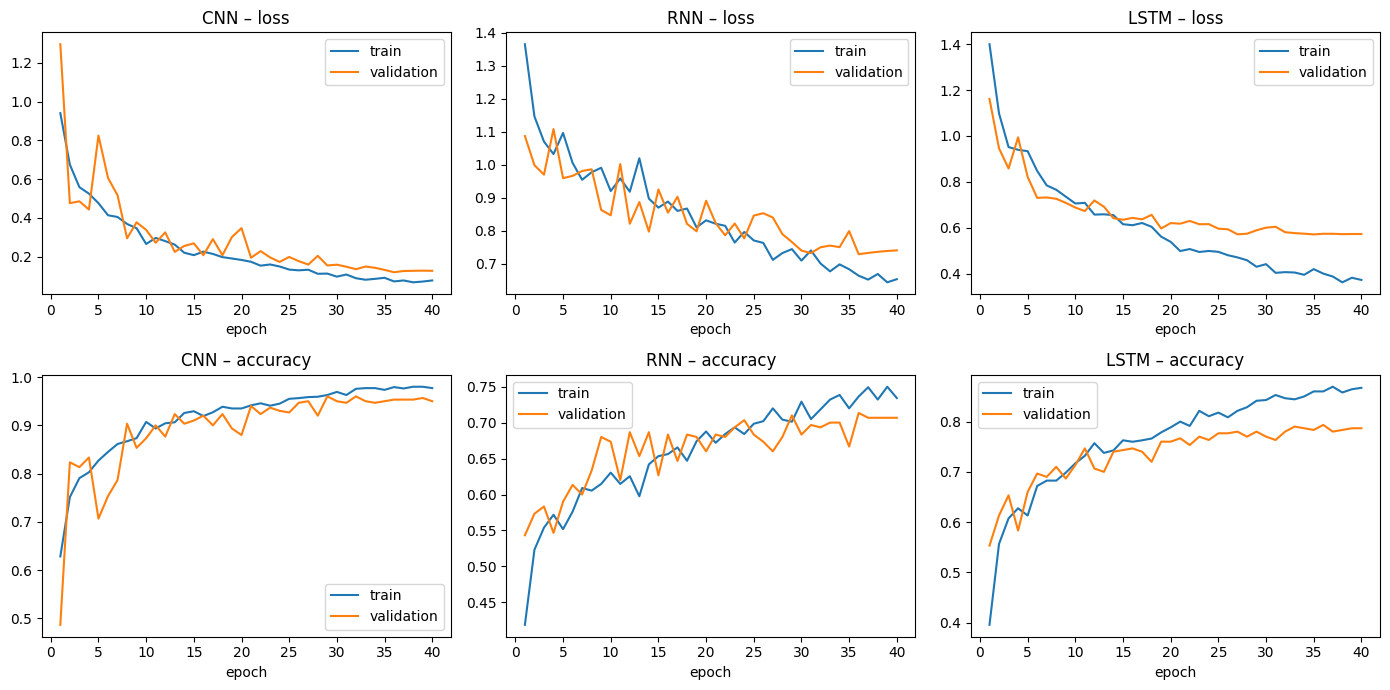

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for j, k in enumerate(("CNN", "RNN", "LSTM")):
    h = store[k]["hist"]; ep = range(1, len(h["tr_loss"]) + 1)
    ax[0, j].plot(ep, h["tr_loss"], label="train"); ax[0, j].plot(ep, h["va_loss"], label="validation")
    ax[0, j].set_title(f"{k} – loss"); ax[0, j].set_xlabel("epoch"); ax[0, j].legend()
    ax[1, j].plot(ep, h["tr_acc"], label="train"); ax[1, j].plot(ep, h["va_acc"], label="validation")
    ax[1, j].set_title(f"{k} – accuracy"); ax[1, j].set_xlabel("epoch"); ax[1, j].legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "training_curves.png", dpi=130); plt.show()

### 6.3 Confusion matrices

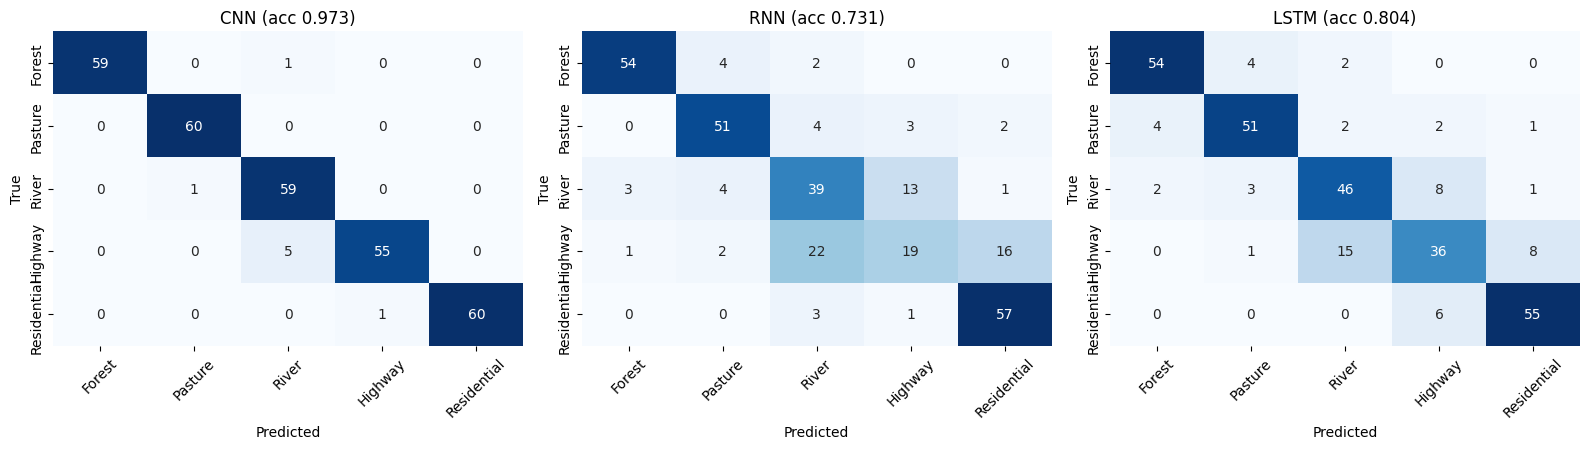


=== CNN classification report ===
              precision    recall  f1-score   support

      Forest      1.000     0.983     0.992        60
     Pasture      0.984     1.000     0.992        60
       River      0.908     0.983     0.944        60
     Highway      0.982     0.917     0.948        60
 Residential      1.000     0.984     0.992        61

    accuracy                          0.973       301
   macro avg      0.975     0.973     0.973       301
weighted avg      0.975     0.973     0.974       301


=== RNN classification report ===
              precision    recall  f1-score   support

      Forest      0.931     0.900     0.915        60
     Pasture      0.836     0.850     0.843        60
       River      0.557     0.650     0.600        60
     Highway      0.528     0.317     0.396        60
 Residential      0.750     0.934     0.832        61

    accuracy                          0.731       301
   macro avg      0.720     0.730     0.717       301
weighte

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for j, k in enumerate(("CNN", "RNN", "LSTM")):
    cm = confusion_matrix(store[k]["y_true"], store[k]["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[j])
    ax[j].set_title(f"{k} (acc {store[k]['res']['accuracy']:.3f})"); ax[j].set_xlabel("Predicted"); ax[j].set_ylabel("True")
    ax[j].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(OUT_DIR / "confusion_matrices.png", dpi=130); plt.show()
for k in ("CNN", "RNN", "LSTM"):
    print(f"\n=== {k} classification report ===")
    print(classification_report(store[k]["y_true"], store[k]["y_pred"], target_names=CLASSES, digits=3))

### 6.4 Multi-class ROC (one-vs-rest) – all three models overlaid
Left: **micro-average** ROC for each model. Right: **per-class** ROC curves (solid = CNN, dashed = LSTM, dotted = RNN).

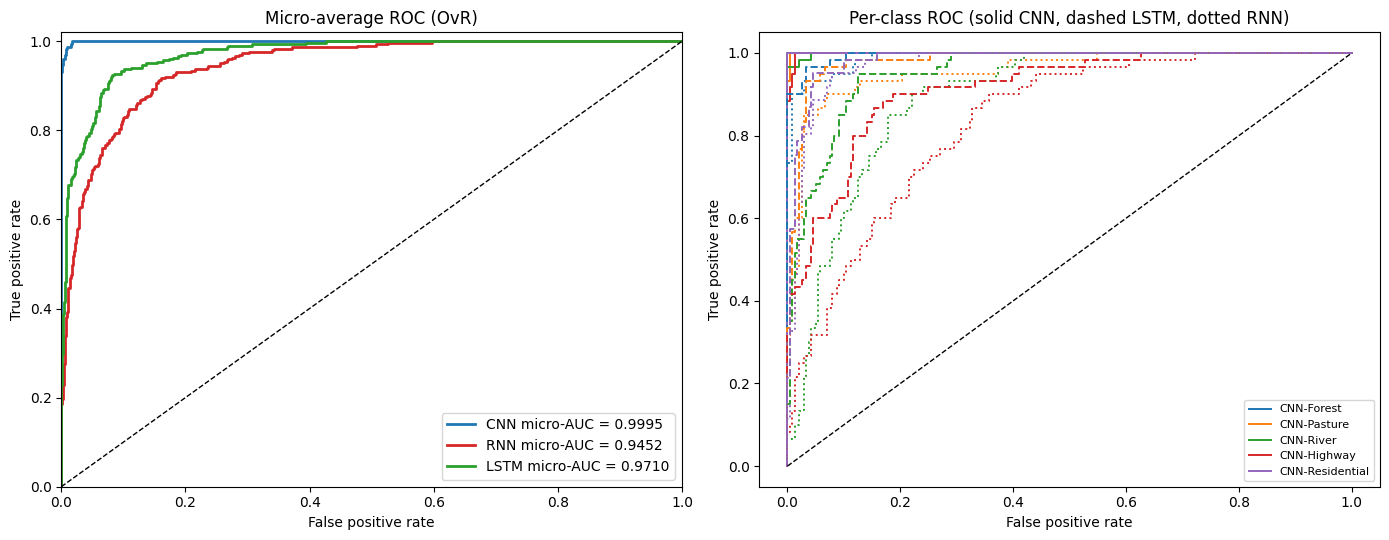

Model  Forest  Pasture  River  Highway  Residential  Macro  Micro
  CNN  1.0000   0.9997 0.9990   0.9990       1.0000 0.9995 0.9995
  RNN  0.9896   0.9564 0.8925   0.8337       0.9730 0.9290 0.9452
 LSTM  0.9951   0.9813 0.9537   0.9138       0.9836 0.9655 0.9710


In [10]:
Y = label_binarize(store["CNN"]["y_true"], classes=range(len(CLASSES)))
colors = {"CNN": "tab:blue", "RNN": "tab:red", "LSTM": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
auc_rows = []
for k in ("CNN", "RNN", "LSTM"):
    pr = store[k]["prob"]
    fpr, tpr, _ = roc_curve(Y.ravel(), pr.ravel()); a = auc(fpr, tpr)
    ax[0].plot(fpr, tpr, color=colors[k], lw=2, label=f"{k} micro-AUC = {a:.4f}")
    auc_rows.append({"Model": k, **{c: roc_auc_score(Y[:, i], pr[:, i]) for i, c in enumerate(CLASSES)},
                     "Macro": store[k]["res"]["auc_macro"], "Micro": a})
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_xlim(0, 1); ax[0].set_ylim(0, 1.02)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("Micro-average ROC (OvR)"); ax[0].legend(loc="lower right")
ls = {"CNN": "-", "LSTM": "--", "RNN": ":"}
for k in ("CNN", "RNN", "LSTM"):
    for i, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Y[:, i], store[k]["prob"][:, i])
        ax[1].plot(fpr, tpr, ls[k], color=f"C{i}", lw=1.4, label=f"{k}-{c}" if k == "CNN" else None)
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("Per-class ROC (solid CNN, dashed LSTM, dotted RNN)")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "roc_curves.png", dpi=130); plt.show()
auc_df = pd.DataFrame(auc_rows).round(4); auc_df.to_csv(OUT_DIR / "auc_per_class.csv", index=False)
print(auc_df.to_string(index=False))

## 7. Discussion & conclusion
The numerical findings are summarised in the report (PDF). In short, the CNN is expected to give the highest
accuracy / F1 / AUC with by far the fewest sequence-related failure modes, because
1. **Weight sharing & local receptive fields** – a conv kernel detects the same texture (forest canopy,
   road line, roof pattern) anywhere in the image, with few parameters.
2. **Translation invariance** via pooling – the class does not depend on *where* a feature is.
3. **Row-wise RNN/LSTM** flatten each row into a 192-D vector, destroy horizontal locality, and must
   carry vertical information through 64 sequential steps (vanishing gradients – worst for the plain RNN).
The LSTM's gating gives it longer memory than the plain RNN, so LSTM ≥ RNN, but both remain below the CNN.
print("Done. Outputs in", OUT_DIR)